# Blue/red linear: 10 vs 20 Hz
See `PLANblueredLinear.md`. Data: `BRfreq/blueRed_14OCT26.mat`, run table: `BRexp_14_10_26.xlsx`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat

DIR = "/home/sebas/data/blueRedLinear/BRfreq/"
cells = loadmat(DIR + "blueRed_14OCT26.mat", squeeze_me=True, struct_as_record=False)["testData"]
table = pd.read_excel(DIR + "BRexp_14_10_26.xlsx")

# linear runs share a name, so key by RunNumber (xlsx row order == .mat order)
runs = {r.RunNumber: s for r, s in zip(table.itertuples(), cells)}

## Summary
Check that the `.mat` order matches the xlsx.

In [2]:
summary = pd.DataFrame(
    {
        rn: {
            "name": s.name, "type": s.typeRun, "freq": int(s.freq),
            "n_raw": s.rawData.size, "n_run": s.runData.size,
            "mean": s.runData.mean(), "std": s.runData.std(ddof=1),
        }
        for rn, s in runs.items()
    }
).T
assert (summary["name"].str.split("-").str[0].values == table["Exp"].values).all()
assert (summary["freq"].values == table["Freq"].values).all()
assert (summary["n_run"].values == table["Tials"].values).all()
summary

,name,type,freq,n_raw,n_run,mean,std
R01,RedBase-10Hz-NF,fixed,10,8,8,1.727646,0.098082
R02,BR1-10Hz-NF,linear,10,13,11,1.815214,0.063617
R04,BR1-10Hz-NF,linear,10,13,11,1.786862,0.145749
R05,RedBase-10Hz-YF,fixed,10,8,8,1.694485,0.069365
R06,BR1-10Hz-YF,linear,10,13,11,1.654937,0.112548
R07,BR1-10Hz-YF,linear,10,13,11,1.595094,0.077306
R08,Rggrid-10Hz-NF,grid,10,104,100,1.429646,0.301198
R09,Rggrid-20Hz-NF,grid,20,104,100,1.559852,0.300948
R10,RedBase-20Hz-NF,fixed,20,8,8,1.753694,0.095893
R11,BR1-20Hz-NF,linear,20,13,11,1.714302,0.092407


## Fixed (RedBase)
8 trials per run, 10 Hz vs 20 Hz.

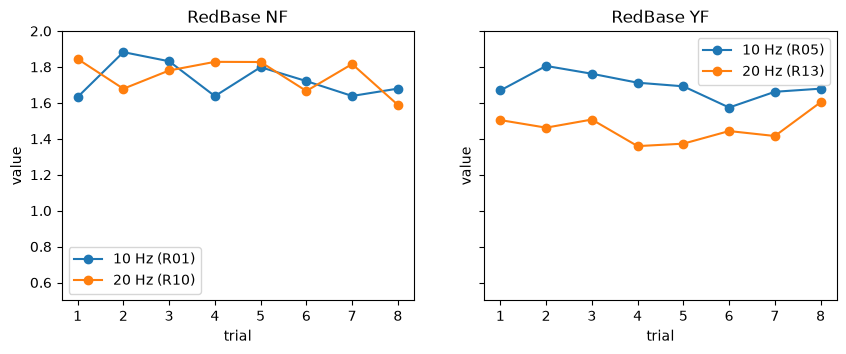

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, filt in zip(axes, ["NF", "YF"]):
    for rn, s in runs.items():
        if s.typeRun == "fixed" and s.name.endswith(filt):
            ax.plot(np.arange(1, 9), s.runData, "o-", label=f"{int(s.freq)} Hz ({rn})")
    ax.set(title=f"RedBase {filt}", xlabel="trial", ylabel="value", ylim=(0.5, 2))
    ax.legend()
plt.show()

## Linear (BR1)
The 2 repeats per condition and their mean. Dashed: RedBase mean at the same frequency and filter.

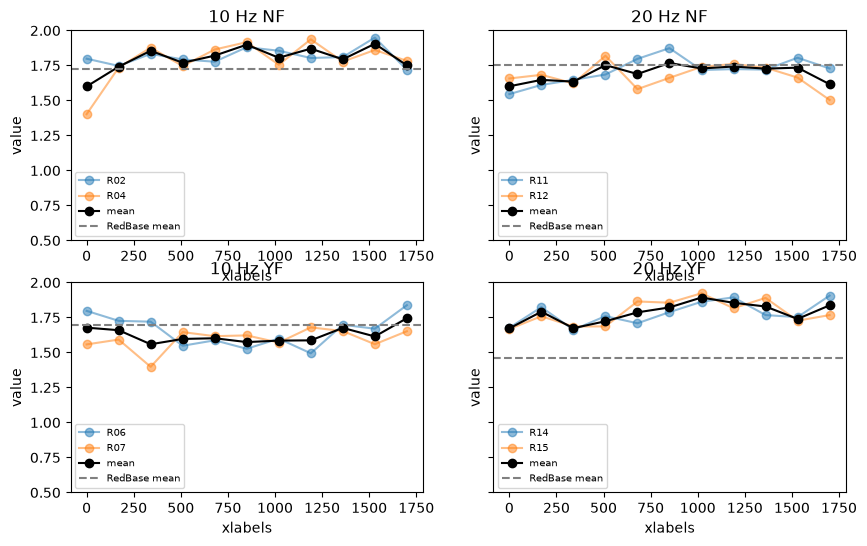

In [4]:
def select(typ, freq, filt):
    return {rn: s for rn, s in runs.items()
            if s.typeRun == typ and s.freq == freq and s.name.endswith(filt)}

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharey=True)
for i, filt in enumerate(["NF", "YF"]):
    for j, freq in enumerate([10, 20]):
        ax = axes[i, j]
        lin = select("linear", freq, filt)
        base = np.mean([s.runData.mean() for s in select("fixed", freq, filt).values()])
        x = next(iter(lin.values())).xlabels
        for rn, s in lin.items():
            ax.plot(x, s.runData, "o-", alpha=0.5, label=rn)
        ax.plot(x, np.mean([s.runData for s in lin.values()], axis=0), "o-", color="k", label="mean")
        ax.axhline(base, color="gray", ls="--", label="RedBase mean")
        ax.set(title=f"{freq} Hz {filt}", xlabel="xlabels", ylabel="value", ylim=(0.5, 2))
        ax.legend(fontsize=7)
plt.show()

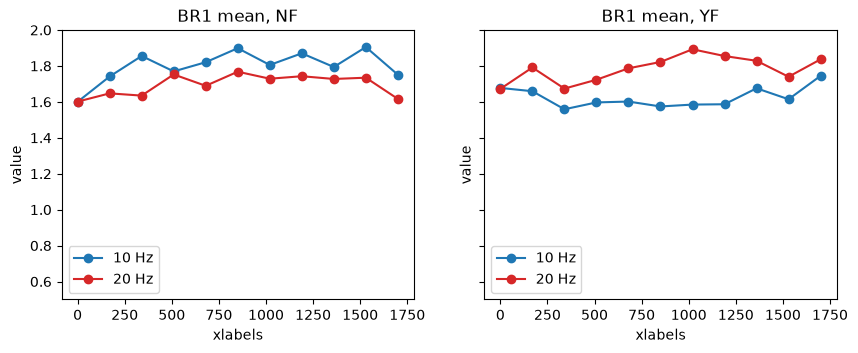

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, filt in zip(axes, ["NF", "YF"]):
    for freq, c in [(10, "tab:blue"), (20, "tab:red")]:
        lin = select("linear", freq, filt)
        x = next(iter(lin.values())).xlabels
        ax.plot(x, np.mean([s.runData for s in lin.values()], axis=0), "o-", color=c, label=f"{freq} Hz")
    ax.set(title=f"BR1 mean, {filt}", xlabel="xlabels", ylabel="value", ylim=(0.5, 2))
    ax.legend()
plt.show()

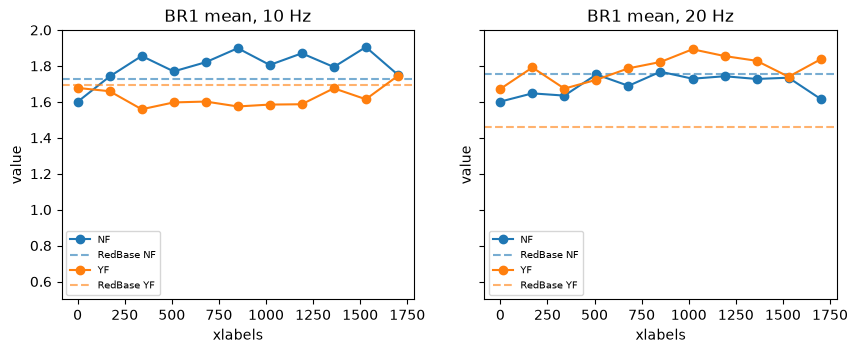

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, freq in zip(axes, [10, 20]):
    for filt, c in [("NF", "tab:blue"), ("YF", "tab:orange")]:
        lin = select("linear", freq, filt)
        x = next(iter(lin.values())).xlabels
        ax.plot(x, np.mean([s.runData for s in lin.values()], axis=0), "o-", color=c, label=filt)
        base = np.mean([s.runData.mean() for s in select("fixed", freq, filt).values()])
        ax.axhline(base, color=c, ls="--", alpha=0.6, label=f"RedBase {filt}")
    ax.set(title=f"BR1 mean, {freq} Hz", xlabel="xlabels", ylabel="value", ylim=(0.5, 2))
    ax.legend(fontsize=7)
plt.show()

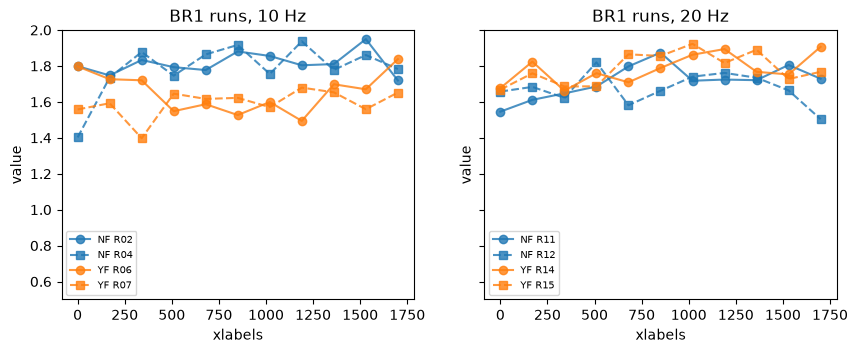

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, freq in zip(axes, [10, 20]):
    for filt, c in [("NF", "tab:blue"), ("YF", "tab:orange")]:
        for k, (rn, s) in enumerate(select("linear", freq, filt).items()):
            ax.plot(s.xlabels, s.runData, "o-" if k == 0 else "s--", color=c, alpha=0.8, label=f"{filt} {rn}")
    ax.set(title=f"BR1 runs, {freq} Hz", xlabel="xlabels", ylabel="value", ylim=(0.5, 2))
    ax.legend(fontsize=7)
plt.show()

### BR1 as percent change from RedBase
Each trial is compared to one baseline value per condition (mean of the 8 RedBase trials at the same frequency and filter): (value - base) / base * 100. Then the mean over the 2 runs.

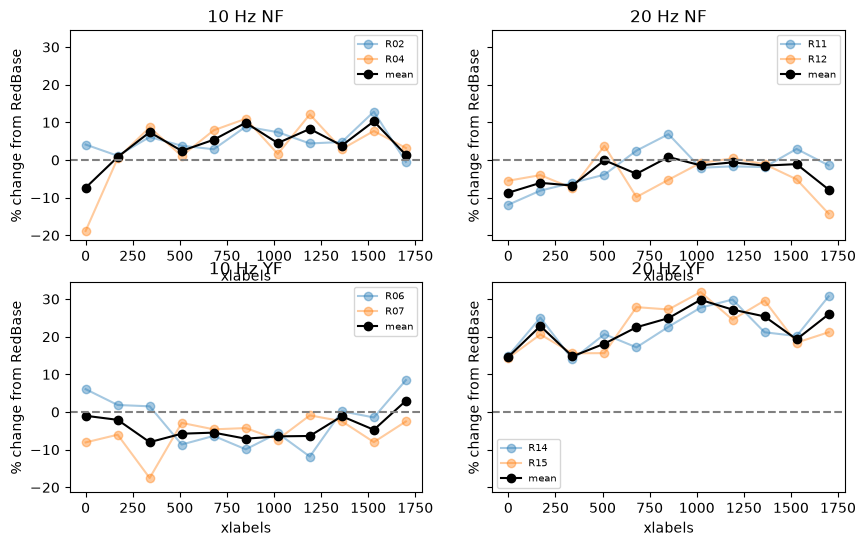

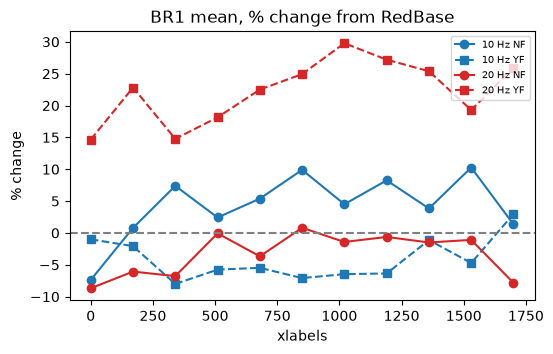

In [8]:
pct, pct_mean = {}, {}
for freq in [10, 20]:
    for filt in ["NF", "YF"]:
        base = np.mean([s.runData for s in select("fixed", freq, filt).values()])
        lin = select("linear", freq, filt)
        pct[freq, filt] = {rn: (s.runData - base) / base * 100 for rn, s in lin.items()}
        pct_mean[freq, filt] = np.mean(list(pct[freq, filt].values()), axis=0)
x = next(iter(select("linear", 10, "NF").values())).xlabels

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharey=True)
for i, filt in enumerate(["NF", "YF"]):
    for j, freq in enumerate([10, 20]):
        ax = axes[i, j]
        for rn, v in pct[freq, filt].items():
            ax.plot(x, v, "o-", alpha=0.4, label=rn)
        ax.plot(x, pct_mean[freq, filt], "o-", color="k", label="mean")
        ax.axhline(0, color="gray", ls="--")
        ax.set(title=f"{freq} Hz {filt}", xlabel="xlabels", ylabel="% change from RedBase")
        ax.legend(fontsize=7)
plt.show()

fig, ax = plt.subplots(figsize=(6, 3.5))
for (freq, filt), v in pct_mean.items():
    ax.plot(x, v, "o-" if filt == "NF" else "s--", color="tab:blue" if freq == 10 else "tab:red", label=f"{freq} Hz {filt}")
ax.axhline(0, color="gray", ls="--")
ax.set(title="BR1 mean, % change from RedBase", xlabel="xlabels", ylabel="% change")
ax.legend(fontsize=7)
plt.show()

## Grid (Rggrid)
`sequence` holds 1-based (red, green) indices into `redArray` / `greenArray`, one row per trial in `runData`. Check that `matrix[red, green]` is `runData` placed by `sequence`.

In [9]:
grids = {int(s.freq): s for s in runs.values() if s.typeRun == "grid"}
for freq, s in grids.items():
    r, g = s.sequence.T.astype(int) - 1
    m = np.full((10, 10), np.nan)
    m[r, g] = s.runData
    print(freq, "Hz: matrix matches runData via sequence:", np.allclose(m, s.matrix),
          "| each cell visited once:", len(set(zip(r, g))) == 100)

10 Hz: matrix matches runData via sequence: True | each cell visited once: True
20 Hz: matrix matches runData via sequence: True | each cell visited once: True


### Grid, linear
Top: `runData` in presentation order. Bottom: value vs red level, one line per green level (columns of `matrix`).

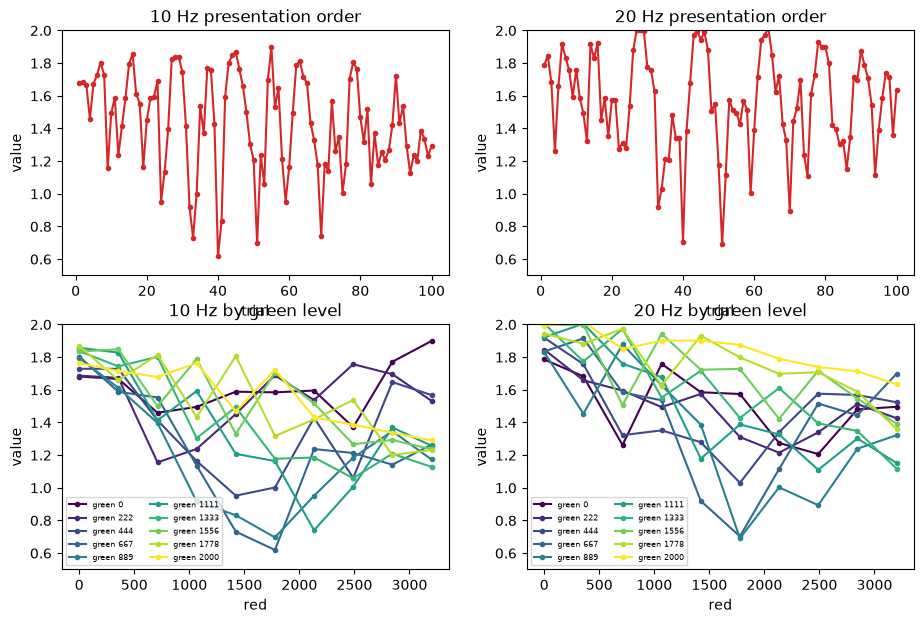

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
cmap = plt.cm.viridis(np.linspace(0, 1, 10))
for j, (freq, s) in enumerate(grids.items()):
    ax = axes[0, j]
    ax.plot(np.arange(1, 101), s.runData, "o-", ms=3, color="tab:red")
    ax.set(title=f"{freq} Hz presentation order", xlabel="trial", ylabel="value", ylim=(0.5, 2))
    ax = axes[1, j]
    for i in range(10):
        ax.plot(s.redArray, s.matrix[:, i], "o-", ms=3, color=cmap[i], label=f"green {s.greenArray[i]:.0f}")
    ax.set(title=f"{freq} Hz by green level", xlabel="red", ylabel="value", ylim=(0.5, 2))
    ax.legend(fontsize=6, ncol=2)
plt.show()

### Grid, raw heatmap
x: red, y: green. Shared color scale.

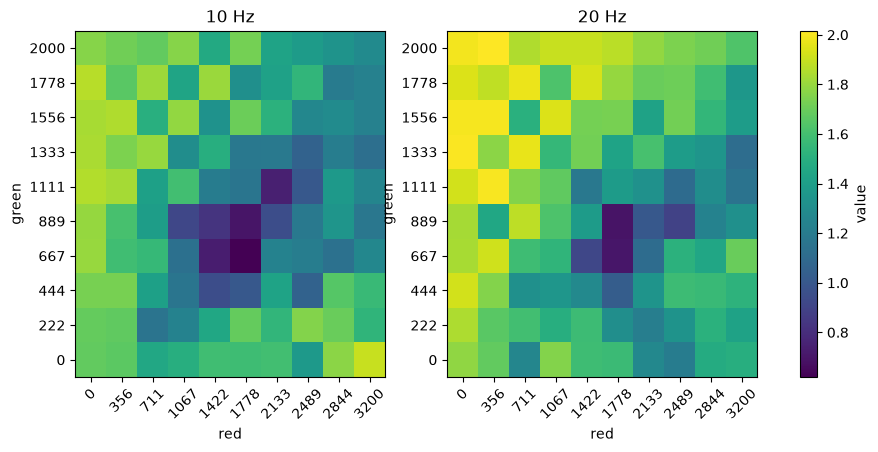

In [11]:
vmin = min(s.matrix.min() for s in grids.values())
vmax = max(s.matrix.max() for s in grids.values())
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (freq, s) in zip(axes, grids.items()):
    im = ax.imshow(s.matrix.T, origin="lower", aspect="auto", vmin=vmin, vmax=vmax, cmap="viridis")
    ax.set_xticks(range(10), [f"{v:.0f}" for v in s.redArray], rotation=45)
    ax.set_yticks(range(10), [f"{v:.0f}" for v in s.greenArray])
    ax.set(title=f"{freq} Hz", xlabel="red", ylabel="green")
fig.colorbar(im, ax=axes, label="value")
plt.show()